# 02 – Tiền xử lý và chia dữ liệu (PHASE 2–3)
Mọi bước dùng code trong `src/`; notebook chỉ gọi và hiển thị kết quả thực tế.
Không huấn luyện mô hình phân lớp trong notebook này.

## 0. Kiểm tra môi trường và đường dẫn dữ liệu

In [1]:
import sys, os, platform, hashlib, warnings
sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, sklearn
from data_loader import *
from preprocessing import *
print(platform.platform(), '| Python', sys.version.split()[0], '| sklearn', sklearn.__version__,
      '| pandas', pd.__version__, '| CPUs', os.cpu_count())
print('Dataset:', RAW_PATH, '| tồn tại:', RAW_PATH.exists(),
      '| sha256:', hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()[:16])

Windows-11-10.0.26300-SP0 | Python 3.12.10 | sklearn 1.9.0 | pandas 3.1.1 | CPUs 32
Dataset: C:\Workspace\decision-tree-vs-naive-bayes_ML\Adult-Income-Classification\data\raw\adult.csv | tồn tại: True | sha256: 250e154ed75714ae


## 1. Làm sạch không học tham số
- Bỏ khoảng trắng đầu/cuối chuỗi; `'?'` → NaN; nhãn `<=50K` → 0, `>50K` → 1.
- Các phép này là quy tắc cố định, không phụ thuộc phân phối dữ liệu → áp dụng trước khi chia không gây rò rỉ.

In [2]:
raw = load_raw(); df = clean(raw)
print(df.shape); print('NaN mỗi cột:', df.isna().sum()[lambda s: s > 0].to_dict())
print('Nhãn:', df[TARGET].value_counts().to_dict())
df.head()

(32561, 15)
NaN mỗi cột: {'workclass': 1836, 'occupation': 1843, 'native.country': 583}
Nhãn: {0: 24720, 1: 7841}


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,0
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,0
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,0


## 2. Nhóm trùng lặp theo nội dung (gồm cả nhãn)
Mỗi nội dung bản ghi đầy đủ là một nhóm; bản ghi duy nhất là nhóm 1 phần tử.

In [3]:
groups = duplicate_group_ids(df); sizes = groups.value_counts()
print('Số nhóm:', groups.nunique(), '| nhóm >1 bản ghi:', (sizes > 1).sum(),
      '| bản ghi trong các nhóm đó:', sizes[sizes > 1].sum())
print('Phân bố kích thước nhóm:', sizes.value_counts().sort_index().to_dict())
print('Mọi nhóm có nhãn đồng nhất:', (df.groupby(groups)[TARGET].nunique() == 1).all())

Số nhóm: 32537 | nhóm >1 bản ghi: 23 | bản ghi trong các nhóm đó: 47
Phân bố kích thước nhóm: {1: 32514, 2: 22, 3: 1}
Mọi nhóm có nhãn đồng nhất: True


## 3. Chia Train / Validation / Test theo nhóm, có phân tầng (PHASE 3)
`StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)` → 20 fold (~5%/fold):
fold 0–2 → Test (15%), fold 3–5 → Validation (15%), fold 6–19 → Train (70%).
Mỗi nhóm trùng nằm trọn trong một fold, nên không bao giờ bị tách sang hai tập.

In [4]:
splits = split_data(df)
summary = split_summary(splits)
summary['fraction_exact'] = (summary['n_samples'] / len(df)).round(5)
summary

,split,n_samples,fraction,n_le50K,n_gt50K,ratio_gt50K,fraction_exact
0,train,22793,0.70,17304,5489,0.2408,0.70001
1,val,4884,0.15,3708,1176,0.2408,0.15000
2,test,4884,0.15,3708,1176,0.2408,0.15000


In [5]:
g = {k: set(groups.loc[v.index]) for k, v in splits.items()}
pairs = [('train','val'), ('train','test'), ('val','test')]
print('Nhóm dùng chung giữa các tập:', {f'{a}&{b}': len(g[a] & g[b]) for a, b in pairs})
print('Tổng bản ghi:', sum(len(v) for v in splits.values()))
pd.read_csv('../data/processed/split_old_vs_new.csv', index_col=0)

Nhóm dùng chung giữa các tập: {'train&val': 0, 'train&test': 0, 'val&test': 0}
Tổng bản ghi: 32561


,new_fraction,old_fraction,new_n_gt50K,old_n_gt50K,new_n_samples,old_n_samples,new_ratio_gt50K,old_ratio_gt50K,rows_moved_out_vs_old
split,,,,,,,,,
train,0.70,0.70,5489,5489,22793,22792,0.2408,0.2408,6818
val,0.15,0.15,1176,1176,4884,4884,0.2408,0.2408,4132
test,0.15,0.15,1176,1176,4884,4885,0.2408,0.2407,4134


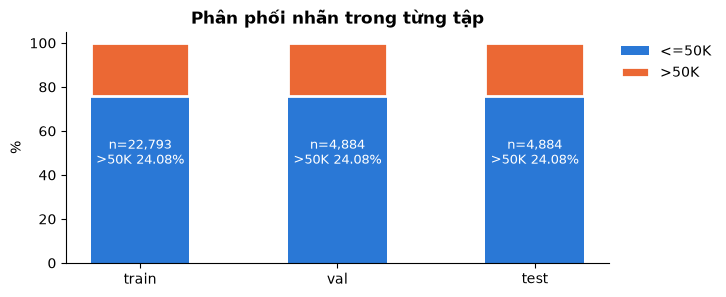

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
names = ['train', 'val', 'test']; s = summary.set_index('split').loc[names]
ax.bar(names, 100 * (1 - s['ratio_gt50K']), color='#2a78d6', label='<=50K', width=0.5)
ax.bar(names, 100 * s['ratio_gt50K'], bottom=100 * (1 - s['ratio_gt50K']), color='#eb6834',
       label='>50K', width=0.5, edgecolor='white', linewidth=2)
for i, (n, r) in enumerate(zip(s['n_samples'], s['ratio_gt50K'])):
    ax.annotate(f'n={n:,}\n>50K {100*r:.2f}%', (i, 50), ha='center', va='center', color='white', fontsize=9)
ax.set_ylabel('%'); ax.set_title('Phân phối nhãn trong từng tập', fontweight='bold')
ax.legend(frameon=False, bbox_to_anchor=(1, 1)); ax.spines[['top', 'right']].set_visible(False)
os.makedirs('../results/figures/preprocessing', exist_ok=True)
fig.savefig('../results/figures/preprocessing/split_label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Pipeline tiền xử lý (PHASE 2) – chỉ fit trên Train
| Mô hình | Thuộc tính số | Thuộc tính phân loại |
|---|---|---|
| Decision Tree | giữ nguyên (cây bất biến với phép biến đổi đơn điệu) | `"Unknown"` → One-Hot (`handle_unknown='ignore'`) |
| CategoricalNB (chính) | KBinsDiscretizer quantile (age, fnlwgt, education.num, hours.per.week); ZeroInflatedDiscretizer (capital.gain/loss) | `"Unknown"` → mã nguyên; hạng mục chưa thấy → mã dành riêng |
| GaussianNB (phụ) | giữ nguyên 6 thuộc tính số | không dùng |

**Vì sao không dùng GaussianNB trên One-Hot cho thí nghiệm chính:** biến One-Hot chỉ nhận 0/1, không thể mô hình bằng phân phối Gaussian; GaussianNB sẽ ước lượng phương sai rất nhỏ cho các cột hiếm và cho mật độ cực lớn/nhỏ, làm xác suất méo mó. CategoricalNB ước lượng trực tiếp P(x_j = giá trị | lớp) bằng tần suất có làm trơn – đúng bản chất dữ liệu phân loại.

In [7]:
Xtr, ytr = xy(splits['train']); Xv, yv = xy(splits['val']); Xte, yte = xy(splits['test'])
pre = {'DT': build_dt_preprocessor().fit(Xtr),
       'CNB': build_cnb_preprocessor().fit(Xtr),
       'GNB': build_gnb_preprocessor().fit(Xtr)}
pd.DataFrame({k: {s: p.transform(X).shape for s, X in [('train', Xtr), ('val', Xv), ('test', Xte)]}
              for k, p in pre.items()})

,DT,CNB,GNB
train,"(22793, 92)","(22793, 13)","(22793, 6)"
val,"(4884, 92)","(4884, 13)","(4884, 6)"
test,"(4884, 92)","(4884, 13)","(4884, 6)"


In [8]:
cnb = pre['CNB']
kb = cnb.named_transformers_['num']; cap = cnb.named_transformers_['capital']
for f, e in zip(kb.feature_names_in_, kb.bin_edges_):
    print(f'{f:15s} biên khoảng (học từ Train):', np.round(e, 1).tolist())
for f, e in zip(CAPITAL_FEATURES, cap.edges_):
    print(f'{f:15s} 0 | các mốc phần dương (học từ Train):', e.tolist())
print('min_categories cho CategoricalNB:', cnb_min_categories(cnb).tolist())

age             biên khoảng (học từ Train): [17.0, 22.0, 26.0, 30.0, 34.0, 37.0, 41.0, 45.0, 51.0, 58.0, 90.0]
fnlwgt          biên khoảng (học từ Train): [12285.0, 65353.0, 106257.0, 131302.0, 159187.0, 178449.0, 196894.0, 220832.0, 261059.0, 329993.0, 1484705.0]
education.num   biên khoảng (học từ Train): [1.0, 7.0, 9.0, 10.0, 11.0, 13.0, 16.0]
hours.per.week  biên khoảng (học từ Train): [1.0, 25.0, 35.0, 40.0, 50.0, 55.0, 99.0]
capital.gain    0 | các mốc phần dương (học từ Train): [3425.0, 7298.0, 14084.0]
capital.loss    0 | các mốc phần dương (học từ Train): [1672.0, 1887.0, 1977.0]
min_categories cho CategoricalNB: [10, 10, 6, 6, 5, 5, 10, 8, 16, 7, 6, 3, 43]


In [9]:
pd.DataFrame(cnb.transform(Xtr.head()), columns=SMOOTH_NUMERIC + CAPITAL_FEATURES + CATEGORICAL_FEATURES)

,age,fnlwgt,education.num,hours.per.week,capital.gain,capital.loss,workclass,marital.status,occupation,relationship,race,sex,native.country
0,9.0,5.0,3.0,3.0,0.0,4.0,7.0,6.0,14.0,4.0,2.0,0.0,38.0
1,8.0,3.0,0.0,3.0,0.0,4.0,3.0,0.0,6.0,4.0,4.0,0.0,38.0
2,6.0,8.0,3.0,3.0,0.0,4.0,3.0,5.0,9.0,3.0,4.0,0.0,38.0
3,4.0,6.0,2.0,3.0,0.0,4.0,3.0,0.0,7.0,4.0,4.0,0.0,38.0
4,5.0,3.0,0.0,3.0,0.0,4.0,3.0,5.0,0.0,4.0,4.0,1.0,38.0


In [10]:
names = pre['DT'].get_feature_names_out()
print(len(names), 'đặc trưng cho Decision Tree, ví dụ:', list(names[:8]), '...')

92 đặc trưng cho Decision Tree, ví dụ: ['num__age', 'num__fnlwgt', 'num__education.num', 'num__capital.gain', 'num__capital.loss', 'num__hours.per.week', 'cat__workclass_Federal-gov', 'cat__workclass_Local-gov'] ...


## 5. Kiểm tra chống rò rỉ

In [11]:
enc = cnb.named_transformers_['cat'].named_steps['ordinal'].enc_
for c, cats in zip(CATEGORICAL_FEATURES, enc.categories_):
    tr = set(Xtr[c].fillna('Unknown'))
    unseen = (set(Xv[c].fillna('Unknown')) | set(Xte[c].fillna('Unknown'))) - tr
    print(f'{c:15s} hạng mục học được == hạng mục của Train: {set(cats) == tr} | chỉ có ở Val/Test: {unseen or "-"}')
# Biên khoảng tính lại chỉ từ Train phải trùng với biên đã học
ref = build_cnb_preprocessor().fit(Xtr).named_transformers_['num'].bin_edges_
print('Biên khoảng tái lập từ Train:', all(np.allclose(a, b) for a, b in zip(ref, kb.bin_edges_)))
alt = build_cnb_preprocessor().fit(pd.concat([Xtr, Xv, Xte])).named_transformers_['num'].bin_edges_
print('Biên khoảng nếu (sai) fit trên toàn bộ dữ liệu có khác không:',
      any(len(a) != len(b) or not np.allclose(a, b) for a, b in zip(alt, kb.bin_edges_)))

workclass       hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
marital.status  hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
occupation      hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
relationship    hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
race            hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
sex             hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -
native.country  hạng mục học được == hạng mục của Train: True | chỉ có ở Val/Test: -


Biên khoảng tái lập từ Train: True
Biên khoảng nếu (sai) fit trên toàn bộ dữ liệu có khác không: True


## 6. Lưu kết quả chia dữ liệu

In [12]:
print(save_splits(splits).to_string(index=False))
idx = pd.read_csv('../data/processed/split_indices.csv')
print(idx.shape); idx[idx.dup_group_size > 1].sort_values('dup_group').head(10)

split  n_samples  fraction  n_le50K  n_gt50K  ratio_gt50K
train      22793      0.70    17304     5489       0.2408
  val       4884      0.15     3708     1176       0.2408
 test       4884      0.15     3708     1176       0.2408
(32561, 4)


,row_index,split,dup_group,dup_group_size
6227,6227,train,6227,2
8645,8645,train,6227,2
7615,7615,train,7615,2
32065,32065,train,7615,2
8453,8453,test,7978,2
7978,7978,test,7978,2
12202,12202,train,8356,2
8356,8356,train,8356,2
29604,29604,train,8499,2
8500,8500,train,8499,2


**Tóm tắt.** Ba tập rời nhau theo cả chỉ số lẫn nội dung bản ghi, tổng 32.561, tỷ lệ ~70/15/15, tỷ lệ >50K ≈ 24,08% ở cả ba tập.
Pipeline được định nghĩa trong `src/preprocessing.py` và sẽ được fit lại bên trong từng thí nghiệm (Train khi chọn siêu tham số, Train+Validation khi đánh giá cuối).